<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HECKTORGPT2unfreeze2_3fold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HECKTOR GPT-2 Last 2 Blocks Unfrozen
# HPV Status Prediction | Compact Single-Cell Notebook
# ============================================================

# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
import os, random, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD HECKTOR EXCEL DATA
DATA_FILE = "HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE, quiet=False
    )
    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)
TARGET = "HPV Status"
FEATURES = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise KeyError(f"Required Excel columns missing: {missing}")

# 3. ROBUSTLY NORMALISE TARGET AND SELECT FEATURES
def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0
    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1
    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[TARGET].apply(normalize_target)
invalid_count = int(df["HPV_Label"].isna().sum())
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[FEATURES + ["HPV_Label"]].copy()

if df.empty:
    raise ValueError("No recognised HPV labels found; check the target column.")
counts = df["HPV_Label"].value_counts().reindex([0, 1], fill_value=0)
if (counts < 2).any():
    raise ValueError(f"Insufficient examples for both HPV classes: {counts.to_dict()}")

print("Dataset:", df.shape, "| Invalid/missing target rows dropped:", invalid_count)
print("HPV classes (0=negative, 1=positive):\n", counts)

# 4. STRATIFIED 3-FOLD CROSS-VALIDATION
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

folds = []
for fold, (train_idx, val_idx) in enumerate(
    skf.split(df[FEATURES], df["HPV_Label"]), start=1
):
    train_df = df.iloc[train_idx].copy()
    val_df = df.iloc[val_idx].copy()
    folds.append((train_df, val_df))

    print(f"\nFold {fold}")
    print("Training samples:", len(train_df))
    print("Validation samples:", len(val_df))
    print("Training class counts:",
          np.bincount(train_df["HPV_Label"], minlength=2))
    print("Validation class counts:",
          np.bincount(val_df["HPV_Label"], minlength=2))

print("\n3-fold cross-validation splits created successfully.")

# 5. IMPUTE MISSING FEATURES USING EACH FOLD'S TRAINING DATA ONLY
def impute_fold(train_df, val_df):
    train_df = train_df.copy()
    val_df = val_df.copy()
    fill_values = {}

    for col in FEATURES:
        if pd.api.types.is_numeric_dtype(train_df[col]):
            value = train_df[col].median()
            if pd.isna(value):
                value = 0
        else:
            modes = train_df[col].dropna().astype(str).mode()
            value = modes.iloc[0] if not modes.empty else "Unknown"

        fill_values[col] = value

        for split in (train_df, val_df):
            split[col] = split[col].fillna(value)
            if split[col].dtype == object:
                split[col] = split[col].astype(str).replace(
                    {"": "Unknown", "nan": "Unknown", "None": "Unknown"}
                )

    return train_df, val_df, fill_values

# 6. CONVERT CLINICAL FEATURES INTO TEXT PROMPTS
def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()

def format_stage(x, prefix):
    value = display_value(x)
    if value == "Unknown" or value.upper().startswith(prefix):
        return value
    try:
        n = float(value)
        if n.is_integer():
            return f"{prefix}{int(n)}"
    except ValueError:
        pass
    return f"{prefix}{value}"

def patient_to_text(row):
    labels = {
        "Age": "Age", "Gender": "Gender",
        "Tobacco Consumption": "Tobacco consumption",
        "Alcohol Consumption": "Alcohol consumption",
        "Performance Status": "Performance status",
        "T-stage": "Tumour T stage", "N-stage": "Nodal N stage",
        "M-stage": "Metastatic M stage"
    }
    parts = ["Q: Predict this patient's HPV status from the following HECKTOR clinical information."]
    for col in FEATURES:
        value = display_value(row[col])
        if col in ("T-stage", "N-stage", "M-stage"):
            value = format_stage(row[col], col[0])
        parts.append(f"{labels[col]}: {value}.")
    parts.append("Is this patient HPV positive? Answer Yes or No.\nA:")
    return " ".join(parts)


# 7. LOAD TOKENIZER AND SET TRAINING PARAMETERS
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

BATCH_SIZE, EPOCHS = 64, 500
LEARNING_RATE, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, 0.1

print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)



# 8. BUILD DATASETS AND DATA LOADERS
# 8. BUILD DATASETS AND DATA LOADERS
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            enc = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, label = self.items[i]
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(label, dtype=torch.long)}



# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id
        h = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(h), nn.Dropout(DROPOUT), nn.Linear(h, 128),
            nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        out = self.gpt2(
            input_ids=input_ids, attention_mask=attention_mask,
            use_cache=False, return_dict=True
        ).last_hidden_state
        positions = attention_mask.sum(dim=1) - 1
        pooled = out[torch.arange(out.size(0), device=out.device), positions]
        return self.classifier(pooled)


def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()



# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id
        h = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(h), nn.Dropout(DROPOUT), nn.Linear(h, 128),
            nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        out = self.gpt2(
            input_ids=input_ids, attention_mask=attention_mask,
            use_cache=False, return_dict=True
        ).last_hidden_state
        positions = attention_mask.sum(dim=1) - 1
        pooled = out[torch.arange(out.size(0), device=out.device), positions]
        return self.classifier(pooled)


def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()




# 10. VALIDATION SCORING AND THRESHOLD SELECTION
def get_scores(loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            logits = model(ids, mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels.extend(batch["label"].numpy())
    return np.asarray(scores), np.asarray(labels, dtype=int)


def evaluate_loss(loader):
    model.eval()
    total, n_total = 0.0, 0
    with torch.no_grad():
        for b in loader:
            ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
            labels = b["label"].to(device)
            loss = weighted_loss(model(ids, mask), labels)
            n = len(labels)
            total += loss.item() * n
            n_total += n
    return total / max(n_total, 1)


def choose_threshold(scores, labels):
    thresholds = np.unique(np.r_[0.0, scores, 1.0])
    values = [
        (float(t), balanced_accuracy_score(labels, scores >= t))
        for t in thresholds
    ]
    return max(values, key=lambda x: (x[1], -abs(x[0] - 0.5)))


# 11. TRAIN MODEL AND SAVE BEST VALIDATION CHECKPOINTS FOR EACH FOLD
OUT_DIR = Path("ROC_HECKTOR_GPT2_CLASSIFIER")
OUT_DIR.mkdir(parents=True, exist_ok=True)

fold_runs = []

for fold_number, (original_train_df, original_val_df) in enumerate(folds, start=1):

    print(f"\n{'=' * 15} FOLD {fold_number}/3 {'=' * 15}")

    # Impute using this fold's training data only
    train_df, val_df, fill_values = impute_fold(
        original_train_df, original_val_df
    )

    y_train = train_df["HPV_Label"].to_numpy(dtype=int)
    y_val = val_df["HPV_Label"].to_numpy(dtype=int)

    print(f"Train: n={len(y_train)}, class counts={np.bincount(y_train, minlength=2)}")
    print(f"Validation: n={len(y_val)}, class counts={np.bincount(y_val, minlength=2)}")

    # Convert this fold's data into the original text prompts
    train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
    val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]

    # Original MAX_LENGTH calculation, using this fold's training prompts
    lengths = [
        len(tokenizer.encode(t, add_special_tokens=False))
        for t in train_texts
    ]
    MAX_LENGTH = min(1024, max(32, int(np.ceil(max(lengths) / 8) * 8)))

    print("Max prompt length:", max(lengths), "| MAX_LENGTH:", MAX_LENGTH)

    # Build datasets and loaders
    train_ds = HPVTextDataset(train_texts, y_train)
    val_ds = HPVTextDataset(val_texts, y_val)

    loader_args = {
        "batch_size": BATCH_SIZE,
        "num_workers": 0,
        "pin_memory": torch.cuda.is_available()
    }

    generator = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(
        train_ds, shuffle=True, generator=generator, **loader_args
    )
    val_loader = DataLoader(
        val_ds, shuffle=False, **loader_args
    )

    # Initialise a fresh instance of the original model
    model = HPVNetGPT2Text().to(device)

    # Freeze all GPT-2 parameters
    for param in model.gpt2.parameters():
        param.requires_grad = False

    # Unfreeze the final 2 GPT-2 blocks
    for block in model.gpt2.h[-2:]:
        for param in block.parameters():
            param.requires_grad = True

    # Keep the classifier head trainable
    for param in model.classifier.parameters():
        param.requires_grad = True

    # Calculate class weights using this fold's training labels
    class_counts = np.bincount(y_train, minlength=2)
    class_weights = torch.tensor(
        len(y_train) / (2 * np.maximum(class_counts, 1)),
        dtype=torch.float32,
        device=device
    )

    # Original AdamW optimiser and settings
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # Verify trainable parameters
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    total_params = sum(p.numel() for p in model.parameters())

    print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
    print("Trainable GPT-2 blocks: final 2; classifier head: trainable")

    # Separate checkpoint files for each fold
    fold_dir = OUT_DIR / f"fold_{fold_number}"
    fold_dir.mkdir(parents=True, exist_ok=True)

    paths = {
        "Validation_Loss": fold_dir / "best_model_validation_loss.pth",
        "Validation_ROC_AUC": fold_dir / "best_model_validation_roc_auc.pth",
        "Validation_PR_AUC": fold_dir / "best_model_validation_pr_auc.pth",
        "Validation_Balanced_Accuracy":
            fold_dir / "best_model_validation_balanced_accuracy.pth"
    }

    best = {
        "Validation_Loss": float("inf"),
        "Validation_ROC_AUC": -float("inf"),
        "Validation_PR_AUC": -float("inf"),
        "Validation_Balanced_Accuracy": -float("inf")
    }

    best_info, history = {}, []

    # Original 500-epoch training procedure
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum, n_sum = 0.0, 0

        for b in train_loader:
            ids = b["input_ids"].to(device)
            mask = b["attention_mask"].to(device)
            labels = b["label"].to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = weighted_loss(model(ids, mask), labels)
            loss.backward()
            optimizer.step()

            n = len(labels)
            loss_sum += loss.item() * n
            n_sum += n

        train_loss = loss_sum / max(n_sum, 1)
        val_loss = evaluate_loss(val_loader)
        val_scores, val_labels = get_scores(val_loader)

        val_auc = roc_auc_score(val_labels, val_scores)
        val_ap = average_precision_score(val_labels, val_scores)
        threshold, val_ba = choose_threshold(val_scores, val_labels)

        metrics = {
            "Validation_Loss": val_loss,
            "Validation_ROC_AUC": val_auc,
            "Validation_PR_AUC": val_ap,
            "Validation_Balanced_Accuracy": val_ba
        }

        history.append({
            "Epoch": epoch,
            "Train_Loss": train_loss,
            **metrics,
            "Validation_Threshold": threshold
        })

        for name, value in metrics.items():
            improved = (
                value < best[name]
                if name == "Validation_Loss"
                else value > best[name]
            )

            if improved:
                best[name] = float(value)
                best_info[name] = {
                    "epoch": epoch,
                    "value": float(value),
                    "threshold": threshold
                }
                torch.save(model.state_dict(), paths[name])

        if epoch % 50 == 0:
            print(
                f"Fold {fold_number} | Epoch {epoch}/{EPOCHS} | "
                f"Train Loss={train_loss:.4f} | "
                f"Val Loss={val_loss:.4f} | "
                f"ROC-AUC={val_auc:.4f} | "
                f"PR-AUC={val_ap:.4f} | "
                f"BA={val_ba:.4f} | "
                f"Threshold={threshold:.4f}"
            )

    # Save this fold's training history and checkpoint information
    pd.DataFrame(history).to_csv(
        fold_dir / "training_history.csv", index=False
    )

    pd.DataFrame([
        {"Checkpoint": k, **v, "Path": str(paths[k])}
        for k, v in best_info.items()
    ]).to_csv(
        fold_dir / "best_validation_checkpoints.csv", index=False
    )

    # Keep this fold's information for evaluation in Section 12
    fold_runs.append({
        "fold": fold_number,
        "paths": paths.copy(),
        "best_info": best_info.copy(),
        "val_loader": val_loader
    })

    print(f"Fold {fold_number} training completed.")

# 12. EVALUATE CHECKPOINTS AND AVERAGE RESULTS ACROSS THREE FOLDS
results, predictions_by_model = [], {}

for fold_run in fold_runs:

    fold_number = fold_run["fold"]
    paths = fold_run["paths"]
    best_info = fold_run["best_info"]
    val_loader = fold_run["val_loader"]

    print(f"\n{'=' * 15} EVALUATING FOLD {fold_number}/3 {'=' * 15}")

    for name, path in paths.items():

        # Load the selected checkpoint for this fold
        model = HPVNetGPT2Text().to(device)
        model.load_state_dict(torch.load(path, map_location=device))

        scores, labels = get_scores(val_loader)

        threshold = best_info[name]["threshold"]
        preds = (scores >= threshold).astype(int)

        auc = roc_auc_score(labels, scores)
        ap = average_precision_score(labels, scores)
        ba = balanced_accuracy_score(labels, preds)
        f1 = f1_score(labels, preds, zero_division=0)
        cm = confusion_matrix(labels, preds, labels=[0, 1])

        print(
            f"\n=== Fold {fold_number} | {name} | "
            f"Best epoch {best_info[name]['epoch']} | "
            f"Threshold {threshold:.4f} ==="
        )

        print(classification_report(
            labels, preds, labels=[0, 1],
            target_names=["HPV Negative", "HPV Positive"],
            digits=4, zero_division=0
        ))

        print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)

        print(
            f"Validation ROC-AUC={auc:.4f} | "
            f"PR-AUC={ap:.4f} | BA={ba:.4f} | F1={f1:.4f}"
        )

        results.append({
            "Fold": fold_number,
            "Dataset": "HECKTOR",
            "Model": "GPT-2 Classifier",
            "Checkpoint_Selected_By": name,
            "Best_Epoch": best_info[name]["epoch"],
            "Validation_Threshold": threshold,
            "Test_ROC_AUC": auc,
            "Test_PR_AUC": ap,
            "Test_Balanced_Accuracy": ba,
            "Test_F1": f1,
            "TN": cm[0, 0],
            "FP": cm[0, 1],
            "FN": cm[1, 0],
            "TP": cm[1, 1]
        })

        predictions_by_model[f"Fold_{fold_number}_{name}"] = (
            labels, scores, preds, threshold
        )

        pd.DataFrame({
            "True_Label": labels,
            "HPV_Positive_Score": scores,
            "Predicted_Label": preds,
            "Threshold": threshold
        }).to_csv(
            OUT_DIR / f"fold_{fold_number}_validation_predictions_{name.lower()}.csv",
            index=False
        )


# Save all individual fold results
individual_results_df = pd.DataFrame(results)
individual_results_df.to_csv(
    OUT_DIR / "three_fold_individual_results.csv", index=False
)

# Average the three folds for each checkpoint-selection method
metric_columns = [
    "Best_Epoch",
    "Validation_Threshold",
    "Test_ROC_AUC",
    "Test_PR_AUC",
    "Test_Balanced_Accuracy",
    "Test_F1"
]

results_df = (
    individual_results_df
    .groupby(
        ["Dataset", "Model", "Checkpoint_Selected_By"],
        as_index=False
    )[metric_columns]
    .mean()
)

# Sum confusion-matrix counts across the three validation folds
confusion_totals = (
    individual_results_df
    .groupby(
        ["Dataset", "Model", "Checkpoint_Selected_By"],
        as_index=False
    )[["TN", "FP", "FN", "TP"]]
    .sum()
)

results_df = results_df.merge(
    confusion_totals,
    on=["Dataset", "Model", "Checkpoint_Selected_By"]
)

results_df.to_csv(
    OUT_DIR / "three_fold_average_results.csv", index=False
)

print("\n========== THREE-FOLD AVERAGE RESULTS ==========")
print(results_df.to_string(index=False))

print("\nAll three folds completed successfully.")
print("Individual fold results:",
      OUT_DIR / "three_fold_individual_results.csv")
print("Average results:",
      OUT_DIR / "three_fold_average_results.csv")

# 13. SAVE ROC AND PRECISION-RECALL CURVES
for name, (labels, scores, preds, threshold) in predictions_by_model.items():
    safe = name.lower()
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)

    pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds}).to_csv(
        OUT_DIR / f"roc_coordinates_{safe}.csv", index=False
    )
    pd.DataFrame({"Precision": precision, "Recall": recall}).to_csv(
        OUT_DIR / f"pr_coordinates_{safe}.csv", index=False
    )

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"HECKTOR ROC — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"roc_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"HECKTOR Precision-Recall — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"pr_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

# 14. SAVE SETTINGS AND COMPARISON RESULTS
settings = {
    "Dataset": "HECKTOR", "Model": MODEL_NAME, "Target": "HPV Status",
    "Features": ", ".join(FEATURES), "Number_of_Features": len(FEATURES),
    "Split": "3-fold stratified cross-validation", "Seed": SEED, "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE, "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY, "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH, "Optimizer": "AdamW",
    "Class_Weighted_Loss": True,
    "Class_Weighted_Loss": True,
    "GPT2_Backbone_Frozen": "Partially frozen; final 2 blocks trainable",
    "GPT2_Trainable_Blocks": 2,
    "Checkpoint_Selection": "Validation loss, ROC-AUC, PR-AUC, balanced accuracy",
    "Threshold_Selection": "Maximum validation balanced accuracy"
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC", "Test_Balanced_Accuracy", "Test_F1"
]]
if comparison_file.exists():
    old = pd.read_csv(comparison_file)
    combined = pd.concat([old, comparison], ignore_index=True, sort=False)
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison
combined.to_csv(comparison_file, index=False)

print("\nAll outputs saved to:", OUT_DIR.resolve())
print("Comparison CSV:", comparison_file.resolve())

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 136MB/s]


Dataset: (588, 9) | Invalid/missing target rows dropped: 138
HPV classes (0=negative, 1=positive):
 HPV_Label
0     58
1    530
Name: count, dtype: int64

Fold 1
Training samples: 392
Validation samples: 196
Training class counts: [ 39 353]
Validation class counts: [ 19 177]

Fold 2
Training samples: 392
Validation samples: 196
Training class counts: [ 39 353]
Validation class counts: [ 19 177]

Fold 3
Training samples: 392
Validation samples: 196
Training class counts: [ 38 354]
Validation class counts: [ 20 176]

3-fold cross-validation splits created successfully.


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

...


=== Fold 3 | Validation_ROC_AUC | Best epoch 174 | Threshold 0.4007 ===
              precision    recall  f1-score   support

HPV Negative     0.2571    0.9000    0.4000        20
HPV Positive     0.9841    0.7045    0.8212       176

    accuracy                         0.7245       196
   macro avg     0.6206    0.8023    0.6106       196
weighted avg     0.9099    0.7245    0.7782       196

Confusion matrix [[TN, FP], [FN, TP]]:
 [[ 18   2]
 [ 52 124]]
Validation ROC-AUC=0.8028 | PR-AUC=0.9744 | BA=0.8023 | F1=0.8212


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


=== Fold 3 | Validation_PR_AUC | Best epoch 174 | Threshold 0.4007 ===
              precision    recall  f1-score   support

HPV Negative     0.2571    0.9000    0.4000        20
HPV Positive     0.9841    0.7045    0.8212       176

    accuracy                         0.7245       196
   macro avg     0.6206    0.8023    0.6106       196
weighted avg     0.9099    0.7245    0.7782       196

Confusion matrix [[TN, FP], [FN, TP]]:
 [[ 18   2]
 [ 52 124]]
Validation ROC-AUC=0.8028 | PR-AUC=0.9744 | BA=0.8023 | F1=0.8212


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


=== Fold 3 | Validation_Balanced_Accuracy | Best epoch 174 | Threshold 0.4007 ===
              precision    recall  f1-score   support

HPV Negative     0.2571    0.9000    0.4000        20
HPV Positive     0.9841    0.7045    0.8212       176

    accuracy                         0.7245       196
   macro avg     0.6206    0.8023    0.6106       196
weighted avg     0.9099    0.7245    0.7782       196

Confusion matrix [[TN, FP], [FN, TP]]:
 [[ 18   2]
 [ 52 124]]
Validation ROC-AUC=0.8028 | PR-AUC=0.9744 | BA=0.8023 | F1=0.8212

========== THREE-FOLD AVERAGE RESULTS ==========
Dataset            Model       Checkpoint_Selected_By  Best_Epoch  Validation_Threshold  Test_ROC_AUC  Test_PR_AUC  Test_Balanced_Accuracy  Test_F1  TN  FP  FN  TP
HECKTOR GPT-2 Classifier Validation_Balanced_Accuracy  258.666667              0.477709      0.784018     0.972996                0.788784 0.767040  55   3 197 333
HECKTOR GPT-2 Classifier              Validation_Loss  299.333333              0.48

In [4]:
!pip install -q shap lime

import shap
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


Processing Fold 1/3


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Calculating SHAP values...


PermutationExplainer explainer: 197it [01:07,  2.49it/s]


Calculating LIME explanation...
LIME explanation - Fold 1


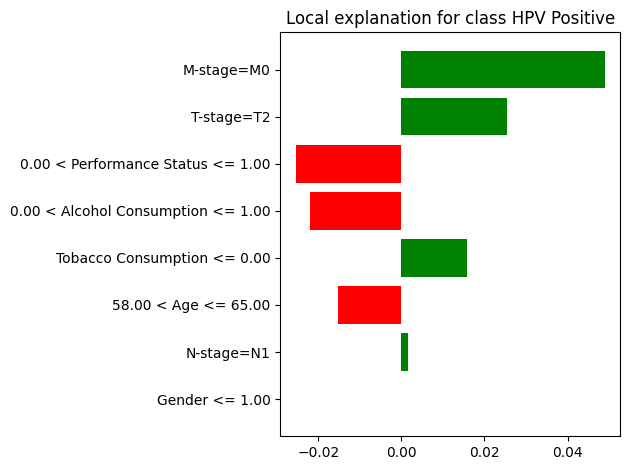


Processing Fold 2/3


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Calculating SHAP values...


PermutationExplainer explainer: 197it [01:07,  2.47it/s]


Calculating LIME explanation...
LIME explanation - Fold 2


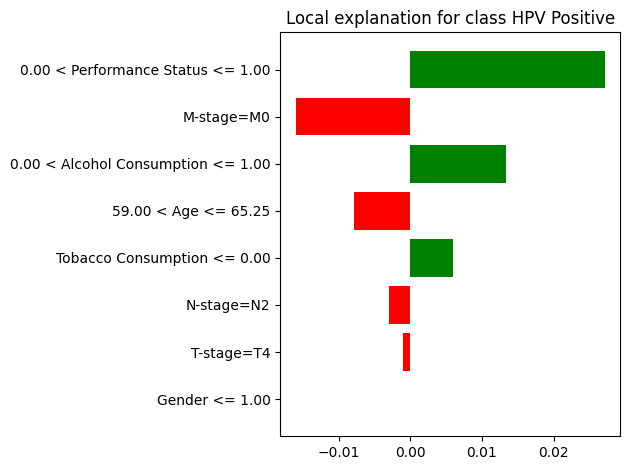


Processing Fold 3/3


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Calculating SHAP values...


PermutationExplainer explainer: 197it [01:06,  2.51it/s]


Calculating LIME explanation...
LIME explanation - Fold 3


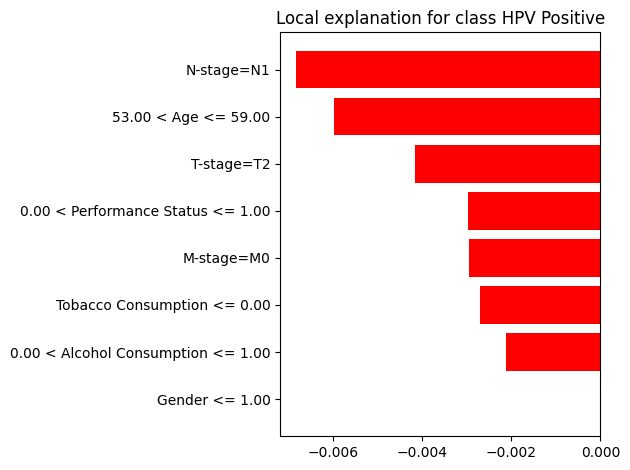


Generating combined three-fold SHAP beeswarm...


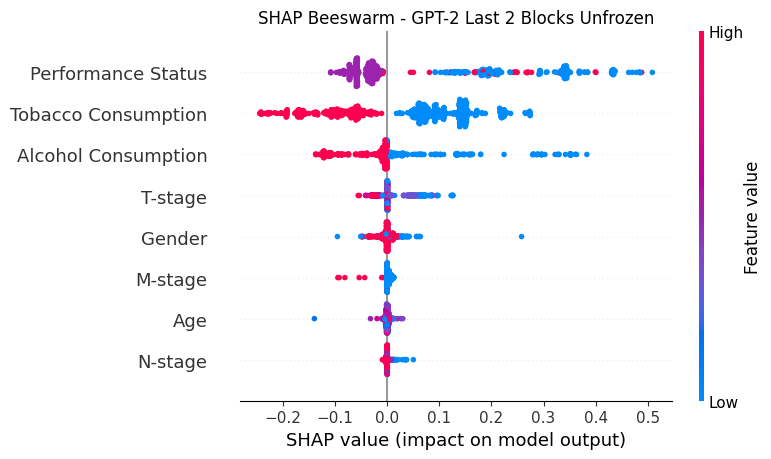


SHAP and LIME completed.
Results saved to: /content/ROC_HECKTOR_GPT2_CLASSIFIER/SHAP_LIME


In [5]:
# ============================================================
# 15. SHAP BEESWARM AND LIME EXPLAINABILITY
# GPT-2 LAST 2 BLOCKS UNFROZEN
# THREE-FOLD CROSS-VALIDATION
# ============================================================

EXPLAIN_DIR = OUT_DIR / "SHAP_LIME"
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_TO_EXPLAIN = "Validation_ROC_AUC"

# Store SHAP values from all three validation folds
all_shap_values = []
all_shap_data = []
all_shap_base_values = []

# Store LIME explanations
lime_results = []

# ------------------------------------------------------------
# 1. PROCESS EACH FOLD
# ------------------------------------------------------------

for fold_run, (original_train_df, original_val_df) in zip(
    fold_runs, folds
):

    fold_number = fold_run["fold"]

    print(f"\nProcessing Fold {fold_number}/3")

    # Recreate fold-specific imputation
    train_df, val_df, fill_values = impute_fold(
        original_train_df,
        original_val_df
    )

    # Recalculate the training prompt length
    train_texts = [
        patient_to_text(row)
        for _, row in train_df.iterrows()
    ]

    lengths = [
        len(tokenizer.encode(t, add_special_tokens=False))
        for t in train_texts
    ]

    fold_max_length = min(
        1024,
        max(32, int(np.ceil(max(lengths) / 8) * 8))
    )

    # --------------------------------------------------------
    # 2. LOAD THE FOLD'S SAVED MODEL
    # --------------------------------------------------------

    model = HPVNetGPT2Text().to(device)

    checkpoint_path = fold_run["paths"][
        CHECKPOINT_TO_EXPLAIN
    ]

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device)
    )

    model.eval()

    # --------------------------------------------------------
    # 3. PREPARE THE EIGHT CLINICAL FEATURES
    # --------------------------------------------------------

    numeric_features = [
        c for c in FEATURES
        if pd.api.types.is_numeric_dtype(train_df[c])
    ]

    categorical_features = [
        c for c in FEATURES
        if c not in numeric_features
    ]

    category_maps = {}

    for col in categorical_features:

        categories = sorted(
            train_df[col].astype(str).unique().tolist()
        )

        if "Unknown" not in categories:
            categories.append("Unknown")

        category_maps[col] = categories

    categorical_indices = [
        FEATURES.index(c) for c in categorical_features
    ]

    categorical_names = {
        FEATURES.index(c): category_maps[c]
        for c in categorical_features
    }

    def encode_features(data):

        encoded = np.zeros(
            (len(data), len(FEATURES)),
            dtype=float
        )

        for j, col in enumerate(FEATURES):

            if col in numeric_features:

                encoded[:, j] = pd.to_numeric(
                    data[col], errors="coerce"
                ).fillna(0).to_numpy()

            else:

                mapping = {
                    value: i
                    for i, value in enumerate(category_maps[col])
                }

                encoded[:, j] = (
                    data[col].astype(str)
                    .map(mapping)
                    .fillna(mapping["Unknown"])
                    .to_numpy()
                )

        return encoded

    def decode_features(encoded):

        encoded = np.asarray(encoded)

        if encoded.ndim == 1:
            encoded = encoded.reshape(1, -1)

        decoded = {}

        for j, col in enumerate(FEATURES):

            if col in numeric_features:

                decoded[col] = encoded[:, j].astype(float)

            else:

                categories = category_maps[col]

                codes = np.rint(encoded[:, j]).astype(int)
                codes = np.clip(codes, 0, len(categories) - 1)

                decoded[col] = [
                    categories[k] for k in codes
                ]

        return pd.DataFrame(decoded, columns=FEATURES)

    train_matrix = encode_features(train_df[FEATURES])
    val_matrix = encode_features(val_df[FEATURES])

    # --------------------------------------------------------
    # 4. MODEL PREDICTION FUNCTION
    # --------------------------------------------------------

    def predict_positive(data):

        data = decode_features(data)

        texts = [
            patient_to_text(row)
            for _, row in data.iterrows()
        ]

        probabilities = []

        model.eval()

        with torch.no_grad():

            for start in range(0, len(texts), 16):

                batch_texts = texts[start:start + 16]

                enc = tokenizer(
                    batch_texts,
                    max_length=fold_max_length,
                    padding="max_length",
                    truncation=True,
                    return_tensors="pt"
                )

                input_ids = enc["input_ids"].to(device)
                attention_mask = enc["attention_mask"].to(device)

                logits = model(input_ids, attention_mask)

                probs = torch.softmax(
                    logits, dim=1
                )[:, 1].cpu().numpy()

                probabilities.extend(probs)

        return np.asarray(probabilities)

    def predict_proba(data):

        positive = predict_positive(data)

        return np.column_stack([
            1 - positive,
            positive
        ])

    # --------------------------------------------------------
    # 5. SHAP VALUES FOR THIS FOLD
    # --------------------------------------------------------

    print("Calculating SHAP values...")

    background = train_matrix[
        :min(40, len(train_matrix))
    ]

    masker = shap.maskers.Independent(
        background,
        max_samples=len(background)
    )

    explainer = shap.Explainer(
        predict_positive,
        masker,
        algorithm="permutation",
        feature_names=FEATURES
    )

    shap_fold = explainer(
        val_matrix,
        max_evals=2 * len(FEATURES) + 1
    )

    all_shap_values.append(shap_fold.values)

    all_shap_data.append(val_matrix)

    all_shap_base_values.append(
        np.asarray(shap_fold.base_values).reshape(-1)
    )

    # --------------------------------------------------------
    # 6. LIME EXPLANATION
    # --------------------------------------------------------

    print("Calculating LIME explanation...")

    lime_explainer = LimeTabularExplainer(
        training_data=train_matrix,
        feature_names=FEATURES,
        class_names=["HPV Negative", "HPV Positive"],
        categorical_features=categorical_indices,
        categorical_names=categorical_names,
        mode="classification",
        discretize_continuous=True,
        random_state=SEED
    )

    # Explain the first validation patient in each fold
    patient_index = 0

    lime_exp = lime_explainer.explain_instance(
        val_matrix[patient_index],
        predict_proba,
        num_features=len(FEATURES),
        num_samples=500,
        labels=[1]
    )

    print(f"LIME explanation - Fold {fold_number}")

    lime_exp.as_pyplot_figure(label=1)
    plt.tight_layout()

    plt.savefig(
        EXPLAIN_DIR / f"LIME_fold_{fold_number}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    for feature, contribution in lime_exp.as_list(label=1):

        lime_results.append({
            "Fold": fold_number,
            "Feature": feature,
            "HPV_Positive_Contribution": contribution
        })


# ------------------------------------------------------------
# 7. COMBINE ALL THREE FOLDS INTO ONE SHAP EXPLANATION
# ------------------------------------------------------------

combined_shap = shap.Explanation(
    values=np.concatenate(all_shap_values, axis=0),
    base_values=np.concatenate(all_shap_base_values),
    data=np.concatenate(all_shap_data, axis=0),
    feature_names=FEATURES
)

# ------------------------------------------------------------
# 8. ONE OVERALL SHAP BEESWARM PLOT
# ------------------------------------------------------------

print("\nGenerating combined three-fold SHAP beeswarm...")

shap.plots.beeswarm(
    combined_shap,
    max_display=len(FEATURES),
    show=False
)

plt.title(
    "SHAP Beeswarm - GPT-2 Last 2 Blocks Unfrozen"
)

plt.tight_layout()

plt.savefig(
    EXPLAIN_DIR / "SHAP_Three_Fold_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 9. SAVE SHAP AND LIME RESULTS
# ------------------------------------------------------------

shap_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_Absolute_SHAP": np.abs(
        combined_shap.values
    ).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.to_csv(
    EXPLAIN_DIR / "SHAP_Feature_Importance.csv",
    index=False
)

pd.DataFrame(lime_results).to_csv(
    EXPLAIN_DIR / "LIME_Results.csv",
    index=False
)

print("\nSHAP and LIME completed.")
print("Results saved to:", EXPLAIN_DIR.resolve())


Processing Fold 1/3


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Generating LIME explanations...
Fold 1: 20 patients explained.

Processing Fold 2/3


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Generating LIME explanations...
Fold 2: 20 patients explained.

Processing Fold 3/3


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Generating LIME explanations...
Fold 3: 20 patients explained.


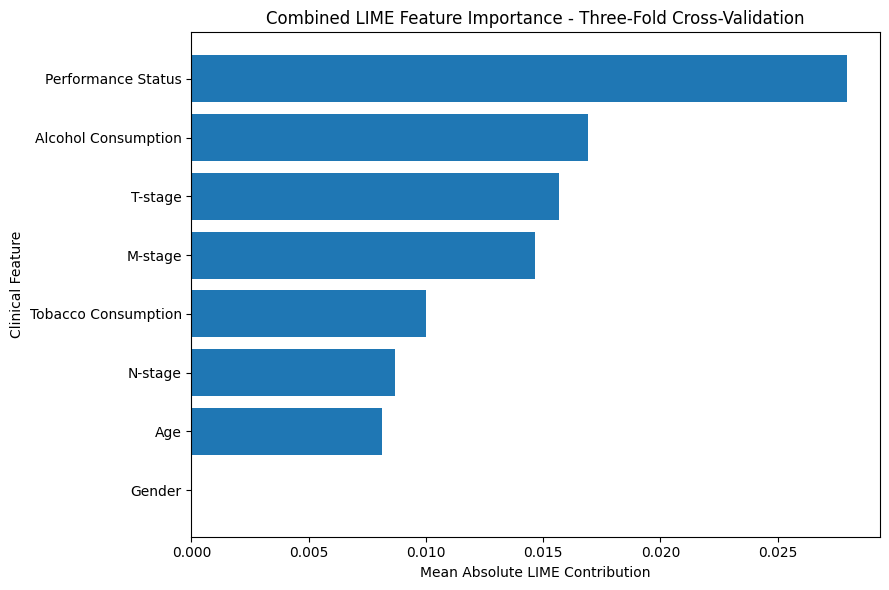


LIME analysis completed successfully.
Combined LIME plot: ROC_HECKTOR_GPT2_CLASSIFIER/LIME_Explanations/LIME_Combined_Feature_Importance.png
Results saved to: /content/ROC_HECKTOR_GPT2_CLASSIFIER/LIME_Explanations


In [6]:
# ============================================================
# 15. COMBINED LIME EXPLAINABILITY
# GPT-2 LAST 2 BLOCKS UNFROZEN
# THREE-FOLD CROSS-VALIDATION
# ============================================================

from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPLAIN_DIR = OUT_DIR / "LIME_Explanations"
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_TO_EXPLAIN = "Validation_ROC_AUC"

LIME_PATIENTS_PER_FOLD = 20
LIME_NUM_SAMPLES = 500

all_lime_results = []

# ============================================================
# PROCESS ALL THREE FOLDS
# ============================================================

for fold_run, (original_train_df, original_val_df) in zip(
    fold_runs, folds
):

    fold_number = fold_run["fold"]

    print(f"\nProcessing Fold {fold_number}/3")

    # Impute using this fold's training data only
    train_df, val_df, fill_values = impute_fold(
        original_train_df,
        original_val_df
    )

    # Recalculate MAX_LENGTH used during training
    train_texts = [
        patient_to_text(row)
        for _, row in train_df.iterrows()
    ]

    lengths = [
        len(tokenizer.encode(t, add_special_tokens=False))
        for t in train_texts
    ]

    fold_max_length = min(
        1024,
        max(32, int(np.ceil(max(lengths) / 8) * 8))
    )

    # --------------------------------------------------------
    # LOAD THE SAVED MODEL CHECKPOINT
    # --------------------------------------------------------

    model = HPVNetGPT2Text().to(device)

    checkpoint_path = fold_run["paths"][
        CHECKPOINT_TO_EXPLAIN
    ]

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device)
    )

    model.eval()

    # --------------------------------------------------------
    # ENCODE CLINICAL FEATURES
    # --------------------------------------------------------

    numeric_features = [
        c for c in FEATURES
        if pd.api.types.is_numeric_dtype(train_df[c])
    ]

    categorical_features = [
        c for c in FEATURES
        if c not in numeric_features
    ]

    category_maps = {}

    for col in categorical_features:

        categories = sorted(
            train_df[col].astype(str).unique().tolist()
        )

        if "Unknown" not in categories:
            categories.append("Unknown")

        category_maps[col] = categories

    categorical_indices = [
        FEATURES.index(c)
        for c in categorical_features
    ]

    categorical_names = {
        FEATURES.index(c): category_maps[c]
        for c in categorical_features
    }

    def encode_features(data):

        encoded = np.zeros(
            (len(data), len(FEATURES)),
            dtype=float
        )

        for j, col in enumerate(FEATURES):

            if col in numeric_features:

                encoded[:, j] = pd.to_numeric(
                    data[col], errors="coerce"
                ).fillna(0).to_numpy()

            else:

                mapping = {
                    value: i
                    for i, value in enumerate(category_maps[col])
                }

                encoded[:, j] = (
                    data[col].astype(str)
                    .map(mapping)
                    .fillna(mapping["Unknown"])
                    .to_numpy()
                )

        return encoded

    def decode_features(encoded):

        encoded = np.asarray(encoded)

        if encoded.ndim == 1:
            encoded = encoded.reshape(1, -1)

        decoded = {}

        for j, col in enumerate(FEATURES):

            if col in numeric_features:

                decoded[col] = encoded[:, j].astype(float)

            else:

                categories = category_maps[col]

                codes = np.rint(encoded[:, j]).astype(int)
                codes = np.clip(
                    codes, 0, len(categories) - 1
                )

                decoded[col] = [
                    categories[k] for k in codes
                ]

        return pd.DataFrame(decoded, columns=FEATURES)

    train_matrix = encode_features(train_df[FEATURES])
    val_matrix = encode_features(val_df[FEATURES])

    # --------------------------------------------------------
    # MODEL PREDICTION FUNCTION
    # --------------------------------------------------------

    def predict_proba(data):

        data = decode_features(data)

        texts = [
            patient_to_text(row)
            for _, row in data.iterrows()
        ]

        probabilities = []

        model.eval()

        with torch.no_grad():

            for start in range(0, len(texts), 16):

                batch_texts = texts[start:start + 16]

                enc = tokenizer(
                    batch_texts,
                    max_length=fold_max_length,
                    padding="max_length",
                    truncation=True,
                    return_tensors="pt"
                )

                input_ids = enc["input_ids"].to(device)
                attention_mask = enc["attention_mask"].to(device)

                logits = model(input_ids, attention_mask)

                probs = torch.softmax(
                    logits, dim=1
                ).cpu().numpy()

                probabilities.extend(probs)

        return np.asarray(probabilities)

    # --------------------------------------------------------
    # LIME EXPLAINER
    # --------------------------------------------------------

    print("Generating LIME explanations...")

    lime_explainer = LimeTabularExplainer(
        training_data=train_matrix,
        feature_names=FEATURES,
        class_names=[
            "HPV Negative",
            "HPV Positive"
        ],
        categorical_features=categorical_indices,
        categorical_names=categorical_names,
        mode="classification",
        discretize_continuous=True,
        random_state=SEED
    )

    number_of_patients = min(
        LIME_PATIENTS_PER_FOLD,
        len(val_matrix)
    )

    for patient_index in range(number_of_patients):

        lime_exp = lime_explainer.explain_instance(
            val_matrix[patient_index],
            predict_proba,
            num_features=len(FEATURES),
            num_samples=LIME_NUM_SAMPLES,
            labels=[1]
        )

        # Save feature contributions
        for feature_index, contribution in lime_exp.as_map()[1]:

            all_lime_results.append({
                "Fold": fold_number,
                "Patient": patient_index + 1,
                "Feature": FEATURES[feature_index],
                "Contribution": contribution
            })

    print(
        f"Fold {fold_number}: "
        f"{number_of_patients} patients explained."
    )


# ============================================================
# COMBINE LIME RESULTS FROM ALL THREE FOLDS
# ============================================================

lime_df = pd.DataFrame(all_lime_results)

lime_summary = (
    lime_df.assign(
        Absolute_Contribution=lime_df["Contribution"].abs()
    )
    .groupby("Feature")
    .agg(
        Mean_Absolute_Contribution=(
            "Absolute_Contribution", "mean"
        ),
        Mean_Signed_Contribution=(
            "Contribution", "mean"
        )
    )
    .reset_index()
    .sort_values(
        "Mean_Absolute_Contribution",
        ascending=True
    )
)

# Save individual patient explanations
lime_df.to_csv(
    EXPLAIN_DIR / "LIME_All_Patient_Results.csv",
    index=False
)

# Save combined feature importance
lime_summary.to_csv(
    EXPLAIN_DIR / "LIME_Combined_Feature_Importance.csv",
    index=False
)


# ============================================================
# ONE COMBINED LIME PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.barh(
    lime_summary["Feature"],
    lime_summary["Mean_Absolute_Contribution"]
)

plt.xlabel("Mean Absolute LIME Contribution")
plt.ylabel("Clinical Feature")

plt.title(
    "Combined LIME Feature Importance - Three-Fold Cross-Validation"
)

plt.tight_layout()

plt.savefig(
    EXPLAIN_DIR / "LIME_Combined_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


print("\nLIME analysis completed successfully.")

print(
    "Combined LIME plot:",
    EXPLAIN_DIR / "LIME_Combined_Feature_Importance.png"
)

print("Results saved to:", EXPLAIN_DIR.resolve())